In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("Output/netflix_cleaned.csv")
print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
display(df.head())

Dataset loaded successfully!
Rows: 8790
Columns: 10


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [4]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB


In [5]:
print("Statistical Summary:")
display(df.describe(include="all"))

Statistical Summary:


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
count,8790,8790,8790,8790,8790,8790,8790.000000,8790,8790,8790
unique,8790,2,8786,4528,86,1713,NaN,14,220,513
top,s8786,Movie,Consequences,Not Given,United States,2020-01-01,NaN,TV-MA,1 Season,"Dramas, International Movies"
freq,1,6126,2,2588,3240,110,NaN,3205,1791,362
mean,NaN,NaN,NaN,NaN,NaN,NaN,2014.183163,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,8.825466,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,1925.000000,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,2017.000000,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,2019.000000,NaN,NaN,NaN


In [6]:
content_counts = df["type"].value_counts()

print("Content Distribution:")
print(content_counts)

Content Distribution:
type
Movie      6126
TV Show    2664
Name: count, dtype: int64


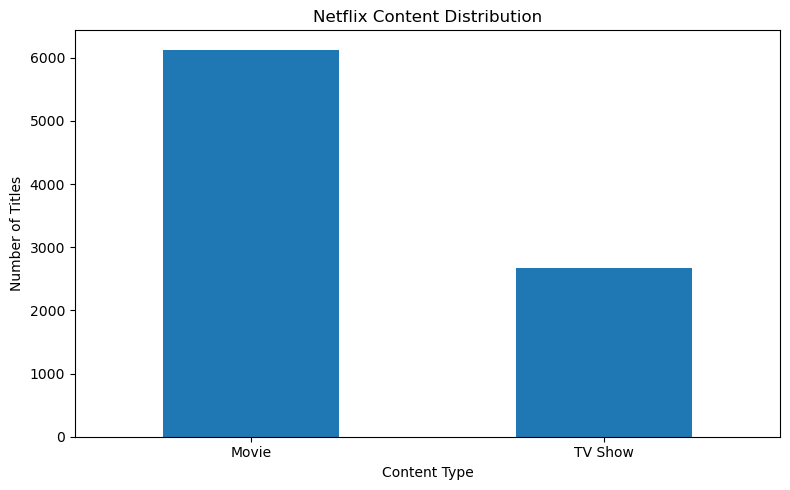

In [7]:
plt.figure(figsize=(8, 5))

content_counts.plot(kind="bar")

plt.title("Netflix Content Distribution")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

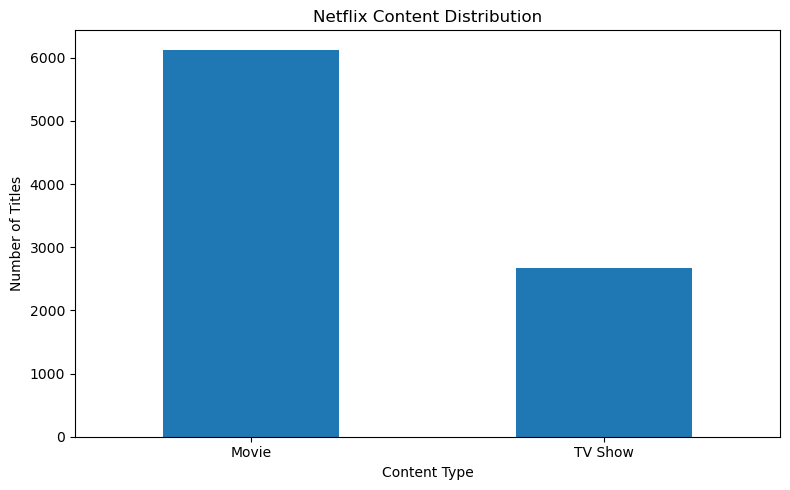

Graph saved successfully!


In [8]:
os.makedirs("Graphs", exist_ok=True)
plt.figure(figsize=(8, 5))
content_counts.plot(kind="bar")

plt.title("Netflix Content Distribution")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "Graphs/content_distribution.png",
    bbox_inches="tight"
)
plt.show()
print("Graph saved successfully!")

In [9]:
# Analyze Netflix content by country

countries = df["country"].dropna().str.split(", ").explode()

# Remove unknown countries
countries = countries[countries != "Unknown"]

# Find the top 10 countries
top_countries = countries.value_counts().head(10)

print("Top 10 Countries with the Most Netflix Content:")
print(top_countries)

Top 10 Countries with the Most Netflix Content:
country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: count, dtype: int64


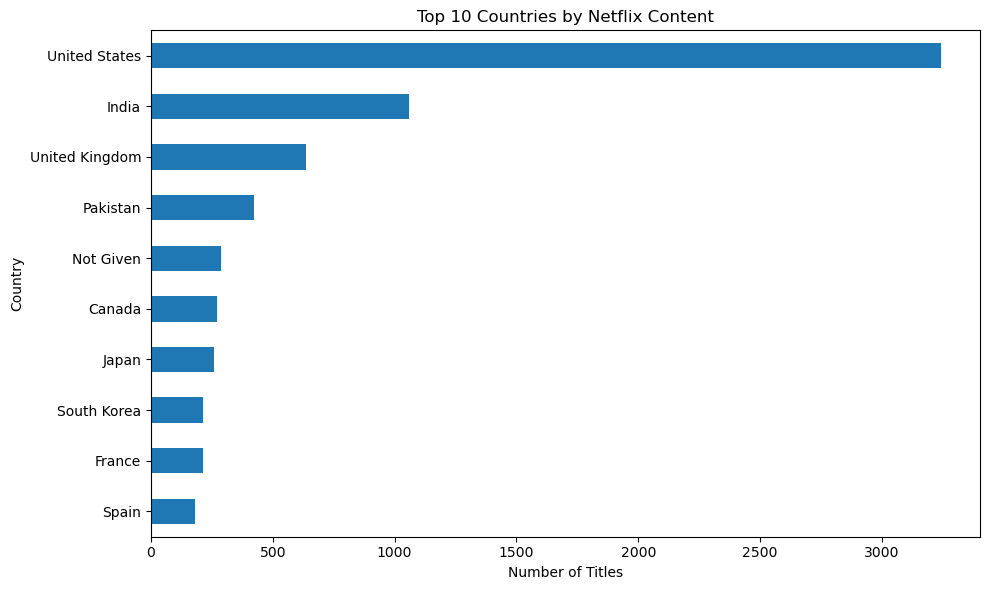

Country graph saved successfully!


In [10]:
plt.figure(figsize=(10, 6))

top_countries.sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Netflix Content")
plt.xlabel("Number of Titles")
plt.ylabel("Country")

plt.tight_layout()
plt.savefig("Graphs/top_countries.png", bbox_inches="tight")
plt.show()

print("Country graph saved successfully!")

In [11]:
# Analyze Netflix content by genre

genres = df["listed_in"].dropna().str.split(", ").explode()

top_genres = genres.value_counts().head(10)

print("Top 10 Netflix Genres:")
print(top_genres)

Top 10 Netflix Genres:
listed_in
International Movies        2752
Dramas                      2426
Comedies                    1674
International TV Shows      1349
Documentaries                869
Action & Adventure           859
TV Dramas                    762
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


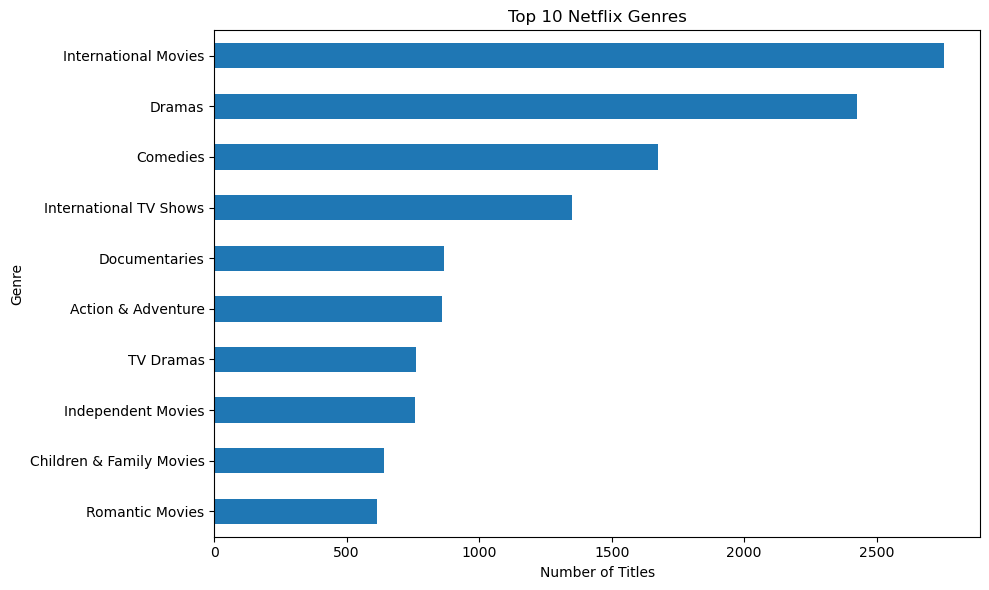

Genre graph saved successfully!


In [12]:
plt.figure(figsize=(10, 6))

top_genres.sort_values().plot(kind="barh")

plt.title("Top 10 Netflix Genres")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")

plt.tight_layout()
plt.savefig("Graphs/top_genres.png", bbox_inches="tight")
plt.show()

print("Genre graph saved successfully!")

In [13]:
# Convert release_year to numeric
df["release_year"] = pd.to_numeric(
    df["release_year"],
    errors="coerce"
)

# Count titles released each year
yearly_counts = df["release_year"].dropna().value_counts().sort_index()

print("Yearly content analysis:")
print(yearly_counts.tail(15))

Yearly content analysis:
release_year
2007      88
2008     135
2009     152
2010     192
2011     185
2012     236
2013     286
2014     352
2015     555
2016     901
2017    1030
2018    1146
2019    1030
2020     953
2021     592
Name: count, dtype: int64


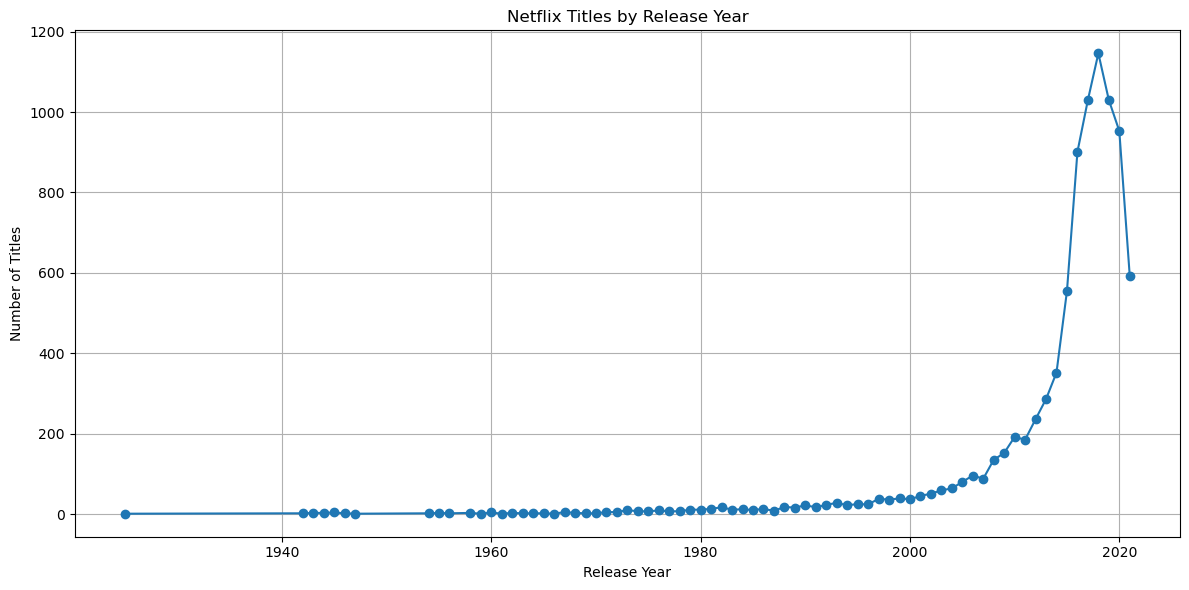

Yearly trend graph saved successfully!


In [14]:
plt.figure(figsize=(12, 6))

plt.plot(
    yearly_counts.index,
    yearly_counts.values,
    marker="o"
)

plt.title("Netflix Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.grid(True)
plt.tight_layout()

plt.savefig("Graphs/yearly_trends.png", bbox_inches="tight")
plt.show()

print("Yearly trend graph saved successfully!")

# Exploratory Data Analysis — Conclusion

## Objectives
- Analyze the distribution of Movies and TV Shows.
- Identify the countries contributing the most content.
- Explore the most common genres.
- Study the distribution of content by release year.

## Key Findings
1. The dataset contains more Movies than TV Shows.
2. The top 10 countries have been identified using country-level counts.
3. The top 10 genres have been identified using genre-level counts.
4. The release-year visualization shows how the content distribution varies across years.

## Conclusion
Exploratory Data Analysis helped identify patterns in the Netflix dataset.
Bar charts and line charts were used to summarize content types, countries,
genres, and release years. These findings provide a foundation for building
a recommendation system and analyzing content trends.